In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge,Lasso
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

In [25]:
df=pd.read_csv("bike(hour).csv")

In [26]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


In [28]:
df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [29]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [30]:
df.fillna(0,inplace=True)

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0000,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0000,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0000,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0000,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0000,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17374,17375,2012-12-31,1,1,12,19,0,1,1,2,0.26,0.2576,0.60,0.1642,11,108,119
17375,17376,2012-12-31,1,1,12,20,0,1,1,2,0.26,0.2576,0.60,0.1642,8,81,89
17376,17377,2012-12-31,1,1,12,21,0,1,1,1,0.26,0.2576,0.60,0.1642,7,83,90
17377,17378,2012-12-31,1,1,12,22,0,1,1,1,0.26,0.2727,0.56,0.1343,13,48,61


In [31]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [32]:
df.shape

(17379, 17)

In [33]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [34]:
X = df.drop(["cnt", "dteday"], axis=1)
Y = df["cnt"]

In [35]:
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [36]:
print("X_train size",x_train.shape)
print("y_train size",y_train.shape)
print("y_train size",x_test.shape)

X_train size (13903, 15)
y_train size (13903,)
y_train size (3476, 15)


In [37]:
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)

In [38]:
ridge=Ridge(alpha=1.0)
ridge.fit(x_train_scaled,y_train)
y_pred_ridge=ridge.predict(x_test_scaled)

In [39]:
lasso=Lasso(alpha=1.0)
lasso.fit(x_train_scaled,y_train)
y_pred_lasso=lasso.predict(x_test_scaled)

In [40]:
##Ridge regression Evalution
ridge_mse=mean_squared_error(y_test,y_pred_ridge)
ridge_mae=mean_absolute_error(y_test,y_pred_ridge)
ridge_r2=r2_score(y_test,y_pred_ridge)

print("MSE:",ridge_mse)
print("MAE:",ridge_mae)
print("R2_score:",ridge_r2)

MSE: 0.0001740626820028972
MAE: 0.009580276346773957
R2_score: 0.9999999945030659


In [41]:
##Lasso regression Evalution
Lasso_mse=mean_squared_error(y_test,y_pred_lasso)
Lasso_mae=mean_absolute_error(y_test,y_pred_lasso)
Lasso_r2=r2_score(y_test,y_pred_lasso)

print("MSE:",Lasso_mse)
print("MAE:",Lasso_mae)
print("R2_score:",Lasso_r2)

MSE: 1.2577723467503747
MAE: 0.8785452759322503
R2_score: 0.9999602792986522


In [42]:
comparison=pd.DataFrame({
    'Actual':y_test.values,
    'y pred lasso':y_pred_lasso,
    'y pred ridge':y_pred_ridge
})

print(comparison.head(10))
    

   Actual  y pred lasso  y pred ridge
0     425    422.642773    425.009498
1      88     88.726249     88.007948
2       4      5.130073      4.007351
3     526    524.235517    525.983539
4      13     14.054929     12.999395
5      32     32.909185     31.999699
6     706    703.491311    705.960160
7      26     27.015809     25.999317
8       2      3.147764      2.011675
9      21     22.064498     21.008580


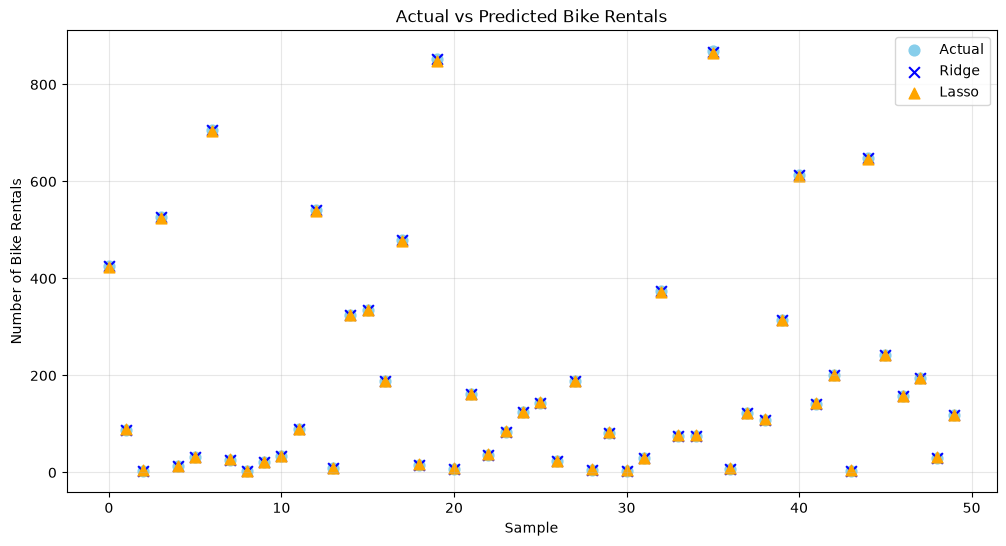

In [43]:
plt.figure(figsize=(12, 6))

plt.scatter(range(50), y_test.values[:50],
            label='Actual', color='skyblue', marker='o', s=60)

plt.scatter(range(50), y_pred_ridge[:50],
            label='Ridge', color='blue', marker='x', s=60)

plt.scatter(range(50), y_pred_lasso[:50],
            label='Lasso', color='orange', marker='^', s=60)

plt.xlabel("Sample")
plt.ylabel("Number of Bike Rentals")
plt.title("Actual vs Predicted Bike Rentals")
plt.legend()
plt.grid(True,alpha=0.3)
plt.show()



# Modification:

In [44]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

In [45]:
linear = LinearRegression()
linear.fit(x_train_scaled, y_train)
y_pred_linear = linear.predict(x_test_scaled)

In [46]:
for name, pred in {
    "Linear": y_pred_linear,
    "Ridge": y_pred_ridge,
    "Lasso": y_pred_lasso
}.items():

    print(name)
    print("MSE:", mean_squared_error(y_test, pred))
    print("MAE:", mean_absolute_error(y_test, pred))
    print("R2 Score:", r2_score(y_test, pred))
    print()

Linear
MSE: 2.693254283081517e-25
MAE: 3.711788580114802e-13
R2 Score: 1.0

Ridge
MSE: 0.0001740626820028972
MAE: 0.009580276346773957
R2 Score: 0.9999999945030659

Lasso
MSE: 1.2577723467503747
MAE: 0.8785452759322503
R2 Score: 0.9999602792986522

